In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os
from sklearn.cluster import KMeans
from google.colab import files

In [3]:
os.makedirs('images', exist_ok=True)

uploaded = files.upload()

for filename in uploaded.keys():
  dest = os.path.join('images', filename)
  os.rename(filename, dest)
  print(f"File '{filename}' Moved To '{dest}'.")

print("\nContents Of Images Folder:")
print(os.listdir('images'))

Saving clock.jpg to clock.jpg
File 'clock.jpg' Moved To 'images/clock.jpg'.

Contents Of Images Folder:
['clock.jpg']


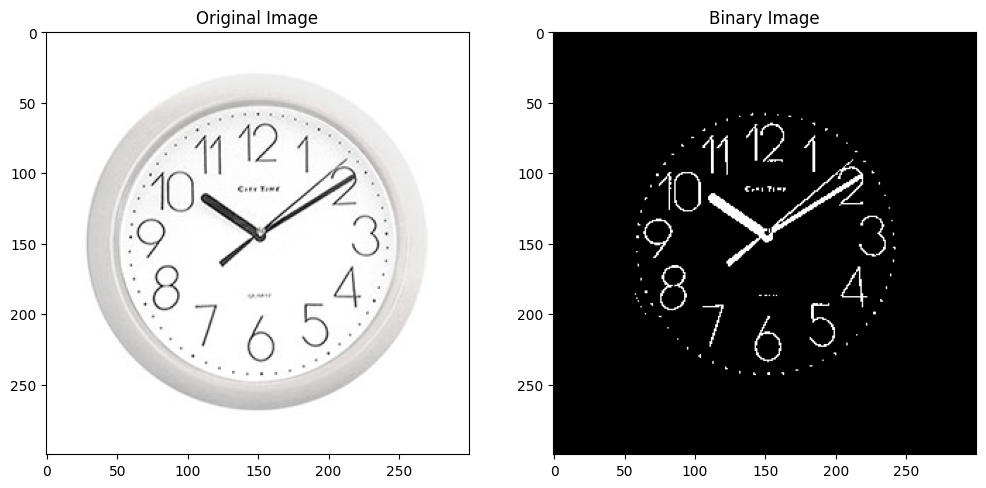

In [12]:
image = cv2.imread('images/clock.jpg')

gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

_, binary = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)

plt.figure(figsize=(12, 7))

plt.subplot(1, 2, 1)
plt.imshow(image[..., ::-1])
plt.title('Original Image')

plt.subplot(1, 2, 2)
plt.imshow(binary, cmap='gray')
plt.title('Binary Image')

plt.show()

Text(0.5, 1.0, 'Opening')

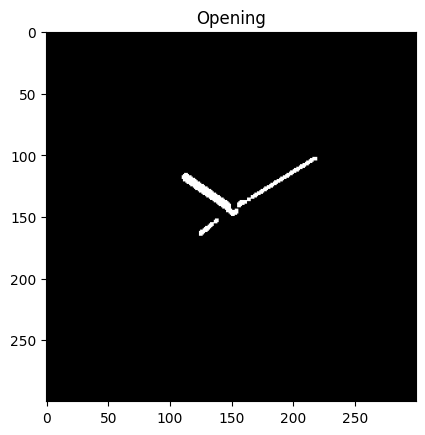

In [5]:
structuring_element = cv2.getStructuringElement(cv2.MORPH_RECT, (3, 3))

opening = cv2.morphologyEx(binary, cv2.MORPH_OPEN, structuring_element)

plt.imshow(opening, cmap='gray')
plt.title('Opening')

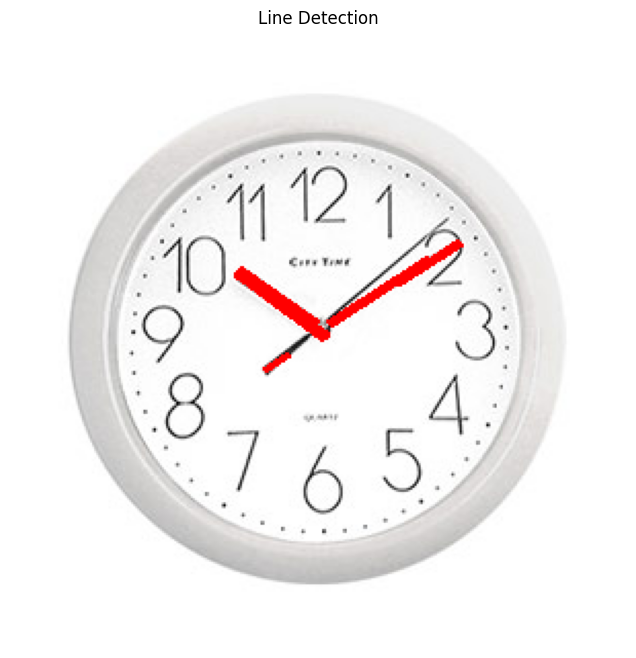

In [8]:
lineThresh = 50
minLineLength = 20
maxLineGap = 10

lines = cv2.HoughLinesP(opening, 1, np.pi / 180, lineThresh, minLineLength, maxLineGap)

X1 = []
X2 = []
Y1 = []
Y2 = []
draw_image = image.copy()

for line in lines:
  x1 = line[0]
  y1 = line[1]
  X2.append(x1)
  Y2.append(y1)

  x2 = line[2]
  y2 = line[3]
  X1.append(x2)
  Y1.append(y2)

  cv2.line(draw_image, (x1, y1), (x2, y2), (0, 0, 255), 2)

plt.figure(figsize=(8, 8))

plt.imshow(draw_image[..., ::-1])
plt.title('Line Detection')
plt.axis('off')

plt.show()

In [9]:
kmeans = KMeans(n_clusters = 2)

X1 = np.array(X1).reshape(-1, 1)
Y1 = np.array(Y1).reshape(-1, 1)
X2 = np.array(X2).reshape(-1, 1)
Y2 = np.array(Y2).reshape(-1, 1)

points = np.hstack((X1, Y1, X2, Y2))
kmeans.fit(points)

results = np.array(kmeans.cluster_centers_, dtype=np.uint8)
print(results)

[[213 105 166 135]
 [149 148 113 124]]


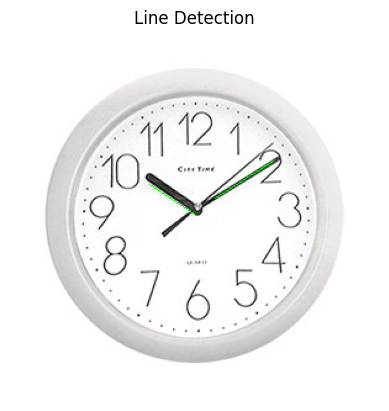

In [11]:
draw_image = image.copy()

for i in range(2):
  x1 = int(results[i][0])
  y1 = int(results[i][1])
  x2 = int(results[i][2])
  y2 = int(results[i][3])

  cv2.line(draw_image, (x1, y1), (x2, y2), (0, 255, 0), 1)

plt.imshow(draw_image[..., ::-1])
plt.title('Line Detection')
plt.axis('off')

plt.show()